#### Relevance score of each text

the topic is **artificial intelligence**. each text gets a score between 0 and 10 that says how much it is about this topic. we cannot label 900 texts by hand, so we use a simple rule based on keywords:
1. count the keywords of the topic in the text (strong keywords like "الذكاء الاصطناعي" or ChatGPT, and weak ones like "بيانات" or "معالج")
2. divide by the number of words, so a long text is not favored
3. add a bonus if the title talks about the topic
4. scale everything to 0-10

the score is a heuristic, not a human judgment. we will check it on examples

In [1]:
import re
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../dataset/arabic_texts.csv")
print(df.shape)

(4555, 4)


##### step 1: keywords

In [2]:
# strong keywords: directly about artificial intelligence (regex, so we match the different forms of a word)
strong = [
    r"ذكاء\s+(?:ال)?اصطناعي",                           # الذكاء الاصطناعي
    r"تعلم\s+(?:ال)?آلة|التعلم\s+الآلي|التعلم\s+العميق",  # machine learning, deep learning
    r"نماذج?\s+(?:ال)?لغوي",                            # language models
    r"\bAI\b",
    r"ChatGPT|GPT|OpenAI|Gemini|Claude|Copilot|LLM|Anthropic|DeepSeek|Qwen|Grok|Llama",
    r"روبوت|شات\s*بوت|وكلاء\s+(?:ال)?ذكاء|شبكات\s+عصبي|خوارزمي",
]

# weak keywords: related to ai, but also used in other tech news
weak = [
    r"نفيديا|Nvidia|NVIDIA",
    r"معالج|شرائح|رقاقة|رقائق",
    r"بيانات",
    r"تقنية|تكنولوجيا",
    r"أتمتة|آلي",
    r"برمج|تطبيق",
]

strong_rx = [re.compile(p, 0 if p == r"\bAI\b" else re.I) for p in strong]
weak_rx = [re.compile(p) for p in weak]

def count_hits(text, patterns):
    return sum(len(p.findall(text)) for p in patterns)

# test on one text
print(count_hits(df["text"][0], strong_rx), count_hits(df["text"][0], weak_rx))

11 1


##### step 2: raw score

In [3]:
n_words = df["text"].str.split().str.len()

strong_hits = df["text"].map(lambda t: count_hits(t, strong_rx))
weak_hits = df["text"].map(lambda t: count_hits(t, weak_rx))
title_hits = df["title"].map(lambda t: count_hits(t, strong_rx))

# keywords per 100 words (weak keywords count 0.3), plus 3 points if the title has a strong keyword
raw = strong_hits / n_words * 100 + 0.3 * weak_hits / n_words * 100 + 3 * (title_hits > 0)
print(raw.describe().round(2))

count    4555.00
mean        1.67
std         2.41
min         0.00
25%         0.11
50%         0.44
75%         1.92
max        11.98
dtype: float64


##### step 3: scale to 0-10

the 95th percentile gets 10 (so one extreme text does not squash all the others). the square root spreads the low scores, otherwise most texts would be close to 0

In [4]:
cap = np.percentile(raw, 95)
x = np.minimum(1, raw / cap)

df["score"] = (10 * np.sqrt(x)).round(1)
print(df["score"].describe().round(2))
print(df.groupby("source")["score"].mean().round(2))

count    4555.00
mean        3.63
std         3.15
min         0.00
25%         1.30
50%         2.50
75%         5.25
max        10.00
Name: score, dtype: float64
source
aitnews         5.80
aljazeera       2.57
arabhardware    2.57
Name: score, dtype: float64


##### step 4: check the scores

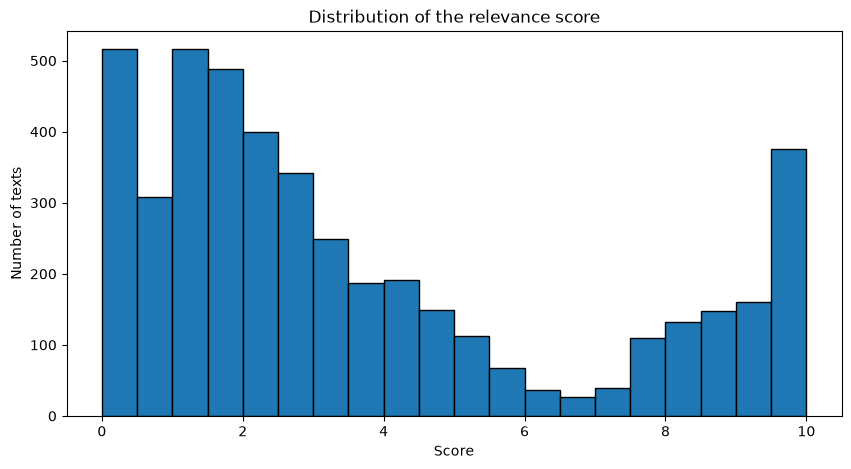

--- score between 0 and 1.5
   انطباعنا عن Battlefield 6: عودة الفوضى العارمة
   ثمار وفيرة ومنافذ موصدة.. مزارعو مأرب يدفعون فاتورة الحرب
   مراجعة لعبة Star Wars Outlaws
   القسائم الغذائية في إيران.. كيف تستخدم وماذا تشتري للأسرة؟
--- score between 3 and 5
   مراجعة شاملة لهاتف Realme GT 8 Pro الجديد
   وداعًا Arc.. متصفح ويب شهير يتوقف نهائيًا في ديسمبر المقبل
   تعرف إلى الترسانة الضخمة من منتجات ASUS في معرض Gamescom 2025
   سامسونج تكشف عن ساعتي Galaxy Watch 9 و Galaxy Watch Ultra 2
--- score between 6 and 8
   من الترانزستور إلى "شات جي بي تي".. رحلة مفاتيح صنعت ثورة الذكاء الاصطناعي
   سناب شات تقتحم عالم البحث الذكي بشراكة تاريخية مع Perplexity
   في قلب الرياض.. السعودية تجمع العالم لبحث معادلات الازدهار في عصر الذكاء الاصطناعي
   احذر.. الذكاء الاصطناعي يستطيع تحديد موقعك من صورة
--- score between 9 and 10.1
   LEAP 2026.. السعودية تبني عملاقًا جديدًا للذكاء الاصطناعي بقوة تصل إلى 1 جيجاواط بحلول 2030
   ملخص مؤتمر DevDay 2025 | أهم ما كشفت عنه OpenAI في مؤتمر المطورين
   م

In [5]:
os.makedirs("../figures", exist_ok=True)

plt.figure(figsize=(10, 5))
plt.hist(df["score"], bins=20, edgecolor="black")
plt.xlabel("Score")
plt.ylabel("Number of texts")
plt.title("Distribution of the relevance score")
plt.savefig("../figures/score_distribution.png", dpi=120, bbox_inches="tight")
plt.show()

# read some examples at different levels, do the scores make sense?
for low, high in [(0, 1.5), (3, 5), (6, 8), (9, 10.1)]:
    print(f"--- score between {low} and {high}")
    for title in df[(df["score"] >= low) & (df["score"] < high)]["title"].sample(4, random_state=0):
        print("  ", title)

##### step 5: discretization

the task asks for a classification, so we also cut the score into 3 classes: low (0-3.5), medium (3.5-6.5) and high (6.5-10)

In [6]:
df["label"] = pd.cut(df["score"], bins=[-0.1, 3.5, 6.5, 10], labels=[0, 1, 2]).astype(int)

print(df["label"].value_counts().sort_index())
print(pd.crosstab(df["source"], df["label"]))

label
0    2869
1     700
2     986
Name: count, dtype: int64
label            0    1    2
source                      
aitnews        520  318  654
aljazeera     1135  162  203
arabhardware  1214  220  129


In [7]:
df.to_csv("../dataset/arabic_texts_scored.csv", index=False, encoding="utf-8")
df[["title", "score", "label", "source"]].head()

,title,score,label,source
0,سيري تُسقِط قائدها.. آبل تعلن رحيل رئيس الذكاء...,9.7,2,aitnews
1,مايكروسوفت تطلق قسمًا جديدًا للسِمات في متجر و...,2.2,0,aitnews
2,هاتف ترامب تحت المجهر.. الكشف عن تفاصيل مُحرجة...,1.1,0,aitnews
3,بوني إيه آي وتويوتا تطلقان سيارات أجرة bZ4X بل...,1.9,0,aitnews
4,فوجي فيلم الشرق الأوسط تطلق حزمة حلول لطب القل...,2.3,0,aitnews
